# 30 — Multi-cell-line PDAC: candidate prioritisation and interpretation

**Reproducible analysis accompanying the MSc thesis.** This notebook uses the canonical Jaaks/GDSC–DepMap multi-cell-line unit table and reconstructs the *formal* ranking of **325 measured drug pairs**, using 10-fold **unseen-drug-pair** out-of-fold (OOF) prediction from **HistGradientBoosting, LightGBM and CatBoost**, separately for **two binary response definitions**. No candidate is ranked using a prediction from a model trained on that candidate's drug pair.

The resulting six-component ranking is followed by post-hoc NAVITOCLAX enrichment, leave-one-pair-out drug-level sensitivity, and (when the relevant independently generated files are supplied) quantitative/propensity support and internal cold-drug validation. These analyses **do not rerank candidates**.

**Important distinctions**

- The 325 pairs were *already measured* in the internal screen; this is retrospective OOF prioritisation, **not experimental validation** of untested drug pairs.
- The 10-fold exhaustive `GroupKFold` ranking here is **not** the ten *repeated* `GroupShuffleSplit` validation analysis in notebook 20. Do not report ranking-fold metrics as the model-comparison headline estimates.
- Ten repeated identity-free cold-drug holdouts belong to notebook 20 and are imported for context here, not refitted.
- A separate historical 2,730-pair one-known/one-cold prospective screen appeared in the provided source HTML, but is **not part of the formal thesis top-10**. Its *optional, clearly identified audit* appears at the end and cannot influence the ranking.
- All results are displayed **in memory**. This notebook never writes CSV files, figures, fitted models or directories.

The notebook requires Python with `numpy`, `pandas`, `scipy`, `scikit-learn`, `lightgbm`, `catboost`, `matplotlib` and `IPython`.

## 1. Input datasets and runtime configuration

The notebook automatically locates the canonical 8,450-unit PDAC table at `tables/pdac_multicell_drug_pair_units_with_morgan.csv` and the 325-pair secondary-support table at `tables/candidate_pair_secondary_support.csv`.

The canonical table is retained locally and excluded from GitHub tracking. The secondary-support table is included in the repository. Both paths are resolved relative to the repository root.

The 20 stored expression PCs are used as fixed features for unseen-drug-pair ranking. Secondary-support measures are evaluated after formal ranking and do not alter candidate ranks.

In [ ]:
from __future__ import annotations
from pathlib import Path
import re
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import hypergeom
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Locate the repository root automatically.
REPO_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "notebooks" / "drug_pair_candidate_ranking.ipynb").is_file()),
    None,
)

if REPO_ROOT is None:
    raise FileNotFoundError("Run this notebook inside the thesis repository.")

UNIT_TABLE_PATH = str(
    REPO_ROOT / "tables" / "pdac_multicell_drug_pair_units_with_morgan.csv"
)

SECONDARY_SUPPORT_PATH = str(
    REPO_ROOT / "tables" / "candidate_pair_secondary_support.csv"
)

for label, path in (
    ("UNIT_TABLE_PATH", UNIT_TABLE_PATH),
    ("SECONDARY_SUPPORT_PATH", SECONDARY_SUPPORT_PATH),
):
    if not Path(path).is_file():
        raise FileNotFoundError(f"{label} is missing: {path}")


SEED = 42
N_FOLDS = 10
MODELS = ("hist_gradient_boosting", "lightgbm_gbdt", "catboost")
ENDPOINTS = ("any_positive_label", "majority_label")
EXPECTED_UNITS = 8450
EXPECTED_PAIRS = 325
EXPECTED_MODELS = 26


def read_local_table(path_text, label):
    if not str(path_text).strip():
        raise ValueError(f"Set {label} in the configuration cell before running this section.")
    path = Path(path_text).expanduser()
    if not path.is_file():
        raise FileNotFoundError(f"{label} does not exist: {path}")
    if path.suffix.lower() in (".pkl", ".pickle"):
        return pd.read_pickle(path).copy()
    if path.suffix.lower() in (".csv", ".gz"):
        return pd.read_csv(path, low_memory=False)
    raise ValueError(f"Unsupported {label} format: {path.suffix}. Use .csv or .pkl.")


def normalise_drug(s):
    if pd.isna(s):
        return ""
    return re.sub(r"[^A-Z0-9]+", "", str(s).strip().upper())


def normalise_pair(pair):
    raw = str(pair)
    if "||" in raw:
        parts = raw.split("||")
    elif " + " in raw:
        parts = raw.split(" + ")
    else:
        raise ValueError(f"Unrecognised unordered pair: {raw!r}")
    if len(parts) != 2 or any(not normalise_drug(x) for x in parts):
        raise ValueError(f"Unrecognised unordered pair: {raw!r}")
    return "||".join(sorted(normalise_drug(x) for x in parts))


def pretty_pair(key):
    return " + ".join(str(key).split("||"))

print("Candidate ranking: HGB, LightGBM, CatBoost × both endpoints × 10 exhaustive drug-pair folds")

Candidate ranking: HGB, LightGBM, CatBoost × both endpoints × 10 exhaustive drug-pair folds


## 2. Canonical table validation and endpoint reconstruction

Assert the expected 8,450 × 325 unit grid, 26 PDAC cell lines, both endpoint counts and full pair coverage. Reconstruct `any_positive_label` as `positive_fraction > 0` and `majority_label` using the **strict** `> 0.5` definition. The original dataset's gene-expression PCA scores must be present already.

In [10]:
units = read_local_table(UNIT_TABLE_PATH, "UNIT_TABLE_PATH").reset_index(drop=True)
necessary = {"ModelID", "drug_a_norm", "drug_b_norm", "positive_fraction"}
absent = necessary - set(units.columns)
if absent:
    raise ValueError(f"Canonical unit table lacks columns: {sorted(absent)}")

units["ModelID"] = units["ModelID"].astype(str)
frac = pd.to_numeric(units["positive_fraction"], errors="coerce")
if frac.isna().any() or not frac.between(0, 1).all():
    raise ValueError("positive_fraction must be finite and in [0, 1].")
units["any_positive_label"] = (frac > 0).astype(int)
units["majority_label"] = (frac > 0.5).astype(int)
units["candidate_pair_key"] = [
    "||".join(sorted((normalise_drug(a), normalise_drug(b))))
    for a, b in zip(units["drug_a_norm"], units["drug_b_norm"])
]
if any(not a or not b for a, b in (k.split("||") for k in units["candidate_pair_key"])):
    raise ValueError("Empty compound name after normalization.")
units["candidate_pair"] = units["candidate_pair_key"].map(pretty_pair)
units["unit_row_id"] = np.arange(len(units), dtype=int)

n_cells = units["ModelID"].nunique()
n_pairs = units["candidate_pair_key"].nunique()
if (len(units), n_cells, n_pairs) != (EXPECTED_UNITS, EXPECTED_MODELS, EXPECTED_PAIRS):
    raise ValueError(f"Wrong canonical table: {(len(units), n_cells, n_pairs)}; expected (8450, 26, 325).")
if units.duplicated(["ModelID", "candidate_pair_key"]).any():
    raise ValueError("Repeated ModelID–unordered-pair units found.")
if not units.groupby("candidate_pair_key")["ModelID"].nunique().eq(EXPECTED_MODELS).all():
    raise ValueError("Each drug pair must occur in all 26 PDAC cell lines.")
positives = (int(units["any_positive_label"].sum()), int(units["majority_label"].sum()))
if positives != (1063, 188):
    raise ValueError(f"Unexpected positive endpoint counts: {positives}; expected (1063, 188).")
print(f"Validated: {len(units):,} units × {n_cells} cell lines × {n_pairs} pairs; positives: {positives}.")

Validated: 8,450 units × 26 cell lines × 325 pairs; positives: (1063, 188).


## 3. Order-invariant features and leakage checks

Reconstruct the exact three-model ranking representation from the source notebook: five unordered pharmacological-annotation combinations, the pairwise **mean and absolute difference** of the two 512-bit Morgan fingerprints, and 20 stored expression PCs (**1,049 predictor columns** before category encoding). Drug identity, pair keys, response labels and other response-derived columns are **not predictors**.

In [11]:
annotation_pairs = [
    ("drug_a_target", "drug_b_target", "target_pair_symmetric"),
    ("drug_a_pathway", "drug_b_pathway", "pathway_pair_symmetric"),
    ("drug_a_drug_type", "drug_b_drug_type", "drug_type_pair_symmetric"),
    ("drug_a_drugcomb_target_name_raw", "drug_b_drugcomb_target_name_raw", "drugcomb_target_name_pair_symmetric"),
    ("drug_a_drugcomb_target_type_raw", "drug_b_drugcomb_target_type_raw", "drugcomb_target_type_pair_symmetric"),
]
for a, b, col in annotation_pairs:
    if a not in units or b not in units:
        raise ValueError(f"Missing annotation input columns {a!r} or {b!r}.")
    lhs = units[a].fillna("missing").astype(str)
    rhs = units[b].fillna("missing").astype(str)
    units[col] = np.where(lhs <= rhs, lhs + " || " + rhs, rhs + " || " + lhs)
ANN_COLS = [third for _, _, third in annotation_pairs]

fp_a_cols = sorted((c for c in units if re.fullmatch(r"drug_a_fp_\d+", str(c))), key=lambda c: int(c.rsplit("_", 1)[1]))
fp_b_cols = sorted((c for c in units if re.fullmatch(r"drug_b_fp_\d+", str(c))), key=lambda c: int(c.rsplit("_", 1)[1]))
if (len(fp_a_cols), len(fp_b_cols)) != (512, 512):
    raise ValueError("Require 512 raw Morgan-bit columns for EACH drug.")
if [c.rsplit("_", 1)[1] for c in fp_a_cols] != [c.rsplit("_", 1)[1] for c in fp_b_cols]:
    raise ValueError("Drug A and B fingerprint indices are not aligned.")

a = units[fp_a_cols].apply(pd.to_numeric, errors="coerce").fillna(0).to_numpy(dtype=np.float32)
b = units[fp_b_cols].apply(pd.to_numeric, errors="coerce").fillna(0).to_numpy(dtype=np.float32)
fp_mean = (a + b) / 2.0
fp_abs = np.abs(a - b)
MORGAN_COLS = [f"symmetric_morgan_mean_{i:04d}" for i in range(512)] + [f"symmetric_morgan_absdiff_{i:04d}" for i in range(512)]
units = pd.concat([units, pd.DataFrame(np.hstack((fp_mean, fp_abs)), columns=MORGAN_COLS, index=units.index)], axis=1)
del a, b, fp_mean, fp_abs
PC_COLS = sorted((c for c in units if re.fullmatch(r"expr_pca_\d+", str(c))), key=lambda c: int(c.rsplit("_", 1)[1]))
if len(PC_COLS) != 20:
    raise ValueError(f"Require exactly 20 existing expression principal components, found {len(PC_COLS)}.")
NUM_COLS = MORGAN_COLS + PC_COLS
FEATURE_COLS = ANN_COLS + NUM_COLS
assert len(FEATURE_COLS) == 1049
forbidden = {"ModelID", "candidate_pair_key", "drug_a_norm", "drug_b_norm", "positive_fraction", "any_positive_label", "majority_label", "drug_pair_group"}
assert not forbidden.intersection(FEATURE_COLS)
if units[PC_COLS].apply(pd.to_numeric, errors="coerce").isna().all().any():
    raise ValueError("At least one expression PC has no valid values.")

feature_audit = pd.DataFrame([{
    "symmetric_annotations": len(ANN_COLS), "symmetric_morgan": len(MORGAN_COLS),
    "expression_pcs": len(PC_COLS), "features_before_encoding": len(FEATURE_COLS),
    "direct_pair_or_label_features": len(forbidden.intersection(FEATURE_COLS)),
}])
display(feature_audit)

,symmetric_annotations,symmetric_morgan,expression_pcs,features_before_encoding,direct_pair_or_label_features
0,5,1024,20,1049,0


## 4. Frozen models and training-fold preprocessing

For every held-out drug-pair fold, impute categorical values and one-hot encode using **training-fold** categories, and median-impute numerical variables using **training-fold** medians. Tree-based estimators are not numerically scaled. Model settings and random state follow the attached executed HTML and the reference three-model panel in the thesis.

In [12]:
def make_onehot():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


def make_preprocessor():
    return ColumnTransformer([
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
            ("onehot", make_onehot()),
        ]), ANN_COLS),
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
        ]), NUM_COLS),
    ], remainder="drop", sparse_threshold=0.0, verbose_feature_names_out=False)


def make_model(model):
    if model == "hist_gradient_boosting":
        return HistGradientBoostingClassifier(
            max_iter=200, learning_rate=0.05, max_leaf_nodes=31,
            l2_regularization=1.0, early_stopping=True, random_state=SEED)
    if model == "lightgbm_gbdt":
        return LGBMClassifier(
            n_estimators=300, learning_rate=0.05, num_leaves=31,
            subsample=0.8, colsample_bytree=0.8,
            objective="binary", class_weight="balanced", verbosity=-1,
            n_jobs=-1, random_state=SEED)
    if model == "catboost":
        return CatBoostClassifier(
            iterations=500, depth=4, learning_rate=0.05,
            loss_function="Logloss", eval_metric="AUC", auto_class_weights="Balanced",
            verbose=False, allow_writing_files=False, random_seed=SEED)
    raise KeyError(f"Unknown frozen model: {model}")


def safe_ap(y, scores):
    return float(average_precision_score(y, scores)) if np.unique(y).size > 1 else np.nan


def safe_auc(y, scores):
    return float(roc_auc_score(y, scores)) if np.unique(y).size > 1 else np.nan

splits = list(GroupKFold(n_splits=N_FOLDS).split(units, groups=units["candidate_pair_key"].to_numpy()))
seen_test_ids = np.concatenate([test_idx for _, test_idx in splits])
if len(seen_test_ids) != len(units) or set(seen_test_ids) != set(range(len(units))):
    raise RuntimeError("Out-of-fold splits do not cover every unit exactly once.")
for train_idx, test_idx in splits:
    tr = set(units.iloc[train_idx]["candidate_pair_key"])
    te = set(units.iloc[test_idx]["candidate_pair_key"])
    if tr & te:
        raise RuntimeError("Unseen-drug-pair split leakage: a pair occurs in both partitions.")
print(f"Prepared {N_FOLDS} exhaustive grouped folds; planned fits: {N_FOLDS*len(MODELS)*len(ENDPOINTS)}.")

Prepared 10 exhaustive grouped folds; planned fits: 60.


## 5. Formal exhaustive out-of-fold three-model ranking

**This cell performs 60 model fits and may take several minutes.** Each pair has 26 held-out cell-line predictions for each of six model–endpoint combinations. The model's held-out probabilities are averaged across cell lines *before* ranking pairs. A deterministic alphabetical pair-key tie-break is applied for each component.

In [13]:
oof_rows = []
fold_rows = []
for fold_id, (train_idx, test_idx) in enumerate(splits, start=1):
    train = units.iloc[train_idx]
    test = units.iloc[test_idx]
    preprocessor = make_preprocessor()
    X_train = preprocessor.fit_transform(train[FEATURE_COLS])
    X_test = preprocessor.transform(test[FEATURE_COLS])
    for endpoint in ENDPOINTS:
        y_train = train[endpoint].to_numpy(dtype=int)
        y_test = test[endpoint].to_numpy(dtype=int)
        if np.unique(y_train).size != 2:
            raise ValueError(f"Training fold {fold_id}/{endpoint} contains only one label.")
        for model_name in MODELS:
            clf = make_model(model_name)
            started = time.perf_counter()
            clf.fit(X_train, y_train)
            probability = np.asarray(clf.predict_proba(X_test)[:, 1], dtype=float)
            elapsed = time.perf_counter() - started
            if not np.isfinite(probability).all():
                raise RuntimeError(f"Non-finite prediction for fold {fold_id}/{model_name}/{endpoint}.")
            fold_rows.append({
                "fold": fold_id, "model": model_name, "endpoint": endpoint,
                "n_train_units": len(train), "n_test_units": len(test),
                "n_train_pairs": train["candidate_pair_key"].nunique(),
                "n_test_pairs": test["candidate_pair_key"].nunique(),
                "test_prevalence": float(y_test.mean()),
                "ap": safe_ap(y_test, probability), "roc_auc": safe_auc(y_test, probability),
                "fit_seconds": elapsed,
            })
            preds = test[["unit_row_id", "ModelID", "candidate_pair_key", "candidate_pair"]].copy()
            preds["true_label"] = y_test
            preds["score"] = probability
            preds["fold"] = fold_id
            preds["model"] = model_name
            preds["endpoint"] = endpoint
            oof_rows.append(preds)
    print(f"Fold {fold_id:02d}/{N_FOLDS}: {test['candidate_pair_key'].nunique()} held-out pairs, {len(test)} units")

oof_predictions = pd.concat(oof_rows, ignore_index=True)
fold_metrics = pd.DataFrame(fold_rows)
if len(oof_predictions) != len(units) * len(MODELS) * len(ENDPOINTS):
    raise RuntimeError("OOF prediction row count is incorrect.")
coverage = oof_predictions.groupby(["unit_row_id", "model", "endpoint"]).size()
if len(coverage) != len(units)*6 or not coverage.eq(1).all():
    raise RuntimeError("Exactly one OOF prediction per unit/model/endpoint was expected.")
model_metrics = (fold_metrics.groupby(["endpoint", "model"], as_index=False)
                 .agg(n_folds=("fold", "nunique"), ap_mean=("ap", "mean"), ap_sd=("ap", "std"),
                      roc_auc_mean=("roc_auc", "mean"), roc_auc_sd=("roc_auc", "std")))
print("All OOF coverage checks passed. Note: these ten-fold metrics are for ranking audit, NOT the repeated-split headline model comparison.")
display(model_metrics)

Fold 01/10: 33 held-out pairs, 858 units
Fold 02/10: 33 held-out pairs, 858 units
Fold 03/10: 33 held-out pairs, 858 units
Fold 04/10: 33 held-out pairs, 858 units
Fold 05/10: 33 held-out pairs, 858 units
Fold 06/10: 32 held-out pairs, 832 units
Fold 07/10: 32 held-out pairs, 832 units
Fold 08/10: 32 held-out pairs, 832 units
Fold 09/10: 32 held-out pairs, 832 units
Fold 10/10: 32 held-out pairs, 832 units
All OOF coverage checks passed. Note: these ten-fold metrics are for ranking audit, NOT the repeated-split headline model comparison.


,endpoint,model,n_folds,ap_mean,ap_sd,roc_auc_mean,roc_auc_sd
0,any_positive_label,catboost,10,0.450655,0.118576,0.843484,0.028548
1,any_positive_label,hist_gradient_boosting,10,0.464463,0.120825,0.846405,0.031181
2,any_positive_label,lightgbm_gbdt,10,0.460074,0.116310,0.841786,0.031368
3,majority_label,catboost,10,0.291959,0.157882,0.885664,0.069101
4,majority_label,hist_gradient_boosting,10,0.274392,0.220532,0.894319,0.070639
5,majority_label,lightgbm_gbdt,10,0.301297,0.227262,0.877941,0.094904


## 6. Six-component drug-pair consensus

For component model × endpoint, rank all **325 pairs** by descending *mean held-out probability*. The percentile is `1 − (rank−1)/(325−1)`; the formal consensus is the **unweighted mean** of six such percentiles. Robustness counts component percentiles ≥0.80 and **does not contribute** to ranking. Exact consensus ties are broken by the minimum component percentile, then pair key.

In [14]:
per_pair_scores = (oof_predictions.groupby(
    ["model", "endpoint", "candidate_pair_key", "candidate_pair"], as_index=False)
    .agg(mean_score=("score", "mean"), median_score=("score", "median"),
         n_units=("unit_row_id", "nunique"), n_cell_lines=("ModelID", "nunique")))
if len(per_pair_scores) != EXPECTED_PAIRS * 6 or not per_pair_scores["n_units"].eq(26).all():
    raise RuntimeError("Not all six components score all 325 pairs across 26 cell lines.")
components = []
for (_, _), sub in per_pair_scores.groupby(["model", "endpoint"], sort=True):
    sub = sub.sort_values(["mean_score", "candidate_pair_key"], ascending=[False, True]).reset_index(drop=True).copy()
    sub["rank_by_mean_score"] = np.arange(1, len(sub)+1)
    sub["rank_percentile"] = 1 - (sub["rank_by_mean_score"]-1)/(len(sub)-1)
    sub["top20pct"] = sub["rank_percentile"] >= 0.8
    components.append(sub)
ranking_components = pd.concat(components, ignore_index=True)

consensus = (ranking_components.groupby(["candidate_pair_key", "candidate_pair"], as_index=False)
             .agg(ml_consensus=("rank_percentile", "mean"),
                  robustness_top20=("top20pct", "mean"),
                  min_component_percentile=("rank_percentile", "min"),
                  max_component_percentile=("rank_percentile", "max"),
                  n_components=("rank_percentile", "size")))
endpoint_pct = (ranking_components.groupby(["candidate_pair_key", "endpoint"])["rank_percentile"].mean()
                .unstack("endpoint").reset_index().rename(columns={
                    "any_positive_label": "any_positive_rank_percentile",
                    "majority_label": "majority_positive_rank_percentile",
                }))
consensus = consensus.merge(endpoint_pct, on="candidate_pair_key", validate="one_to_one")
consensus = consensus.sort_values(["ml_consensus", "min_component_percentile", "candidate_pair_key"],
                                 ascending=[False, False, True]).reset_index(drop=True)
consensus["formal_rank"] = np.arange(1, len(consensus) + 1)
if len(consensus) != 325 or not consensus["n_components"].eq(6).all():
    raise RuntimeError("Consensus must have 325 pairs × exactly 6 components.")
formal_top10 = consensus.head(10).copy()
rank_columns = ["formal_rank", "candidate_pair", "ml_consensus", "any_positive_rank_percentile",
                "majority_positive_rank_percentile", "robustness_top20", "min_component_percentile"]
display(formal_top10[rank_columns])

,formal_rank,candidate_pair,ml_consensus,any_positive_rank_percentile,majority_positive_rank_percentile,robustness_top20,min_component_percentile
0,1,NAVITOCLAX + OSI027,0.985597,0.979424,0.991770,1.0,0.975309
1,2,DASATINIB + NAVITOCLAX,0.984053,0.996914,0.971193,1.0,0.953704
2,3,MK2206 + SCH772984,0.983025,0.990741,0.975309,1.0,0.944444
3,4,MK2206 + NAVITOCLAX,0.977881,0.982510,0.973251,1.0,0.953704
4,5,LINSITINIB + NAVITOCLAX,0.972222,0.980453,0.963992,1.0,0.944444
5,6,NAVITOCLAX + TRAMETINIB,0.970679,0.969136,0.972222,1.0,0.956790
6,7,ERLOTINIB + NAVITOCLAX,0.969136,0.975309,0.962963,1.0,0.950617
7,8,MK2206 + TRAMETINIB,0.962963,0.942387,0.983539,1.0,0.876543
8,9,SCH772984 + TASELISIB,0.961934,0.929012,0.994856,1.0,0.870370
9,10,LAPATINIB + NAVITOCLAX,0.958333,0.990741,0.925926,1.0,0.876543


## 7. Thesis top-10 reconciliation (read-only)

The comparison below **does not force predictions, reorder candidates, or repair discrepancies**. Scores in the current thesis are displayed alongside the freshly computed values. Differences should be investigated before publication (for example, source-table versions, library versions or preprocessing changes).

In [15]:
thesis_reference = pd.DataFrame([
    (1, "NAVITOCLAX||OSI027", .986, .979, .992),
    (2, "DASATINIB||NAVITOCLAX", .984, .997, .971),
    (3, "MK2206||SCH772984", .983, .991, .975),
    (4, "MK2206||NAVITOCLAX", .978, .983, .973),
    (5, "LINSITINIB||NAVITOCLAX", .972, .980, .964),
    (6, "NAVITOCLAX||TRAMETINIB", .971, .969, .972),
    (7, "ERLOTINIB||NAVITOCLAX", .969, .975, .963),
    (8, "MK2206||TRAMETINIB", .963, .942, .984),
    (9, "SCH772984||TASELISIB", .962, .929, .995),
    (10, "LAPATINIB||NAVITOCLAX", .958, .991, .926),
], columns=["formal_rank", "thesis_pair_key", "thesis_ml", "thesis_any", "thesis_majority"])
compare_top10 = thesis_reference.merge(formal_top10, on="formal_rank", how="left", validate="one_to_one")
compare_top10["same_pair"] = compare_top10["candidate_pair_key"].eq(compare_top10["thesis_pair_key"])
compare_top10["ml_delta"] = compare_top10["ml_consensus"] - compare_top10["thesis_ml"]
compare_top10["score_match_3dp"] = np.isclose(compare_top10["ml_consensus"], compare_top10["thesis_ml"], atol=.00051, rtol=0)
display(compare_top10[["formal_rank", "thesis_pair_key", "candidate_pair_key", "same_pair", "thesis_ml", "ml_consensus", "ml_delta", "score_match_3dp"]])
if not compare_top10["same_pair"].all() or not compare_top10["score_match_3dp"].all():
    warnings.warn("Computed candidate ranking differs from thesis top 10. Do not publish without reconciling it.")
else:
    print("Top-10 pair identities and rounded ML consensus agree with the thesis.")

,formal_rank,thesis_pair_key,candidate_pair_key,same_pair,thesis_ml,ml_consensus,ml_delta,score_match_3dp
0,1,NAVITOCLAX||OSI027,NAVITOCLAX||OSI027,True,0.986,0.985597,-0.000403,True
1,2,DASATINIB||NAVITOCLAX,DASATINIB||NAVITOCLAX,True,0.984,0.984053,0.000053,True
2,3,MK2206||SCH772984,MK2206||SCH772984,True,0.983,0.983025,0.000025,True
3,4,MK2206||NAVITOCLAX,MK2206||NAVITOCLAX,True,0.978,0.977881,-0.000119,True
4,5,LINSITINIB||NAVITOCLAX,LINSITINIB||NAVITOCLAX,True,0.972,0.972222,0.000222,True
5,6,NAVITOCLAX||TRAMETINIB,NAVITOCLAX||TRAMETINIB,True,0.971,0.970679,-0.000321,True
6,7,ERLOTINIB||NAVITOCLAX,ERLOTINIB||NAVITOCLAX,True,0.969,0.969136,0.000136,True
7,8,MK2206||TRAMETINIB,MK2206||TRAMETINIB,True,0.963,0.962963,-0.000037,True
8,9,SCH772984||TASELISIB,SCH772984||TASELISIB,True,0.962,0.961934,-0.000066,True
9,10,LAPATINIB||NAVITOCLAX,LAPATINIB||NAVITOCLAX,True,0.958,0.958333,0.000333,True


Top-10 pair identities and rounded ML consensus agree with the thesis.


## 8. Post-hoc recurrent-drug sensitivity and NAVITOCLAX enrichment

One-sided hypergeometric enrichment asks whether NAVITOCLAX-containing pairs are unusually frequent in the already fixed candidate list, relative to their abundance among all 325 measured pairs. Leave-one-pair-out constituent-drug mean scores quantify whether a candidate ranks higher than the average other pair containing either drug; these summaries **never change the ranking**.

In [16]:
pairs = consensus.copy()
parts = pairs["candidate_pair_key"].str.split("||", regex=False, expand=True)
if parts.shape[1] != 2:
    raise ValueError("Invalid canonical pair delimiter.")
pairs["drug_a"], pairs["drug_b"] = parts[0], parts[1]
pairs["contains_navitoclax"] = pairs["drug_a"].eq("NAVITOCLAX") | pairs["drug_b"].eq("NAVITOCLAX")
N, K = len(pairs), int(pairs["contains_navitoclax"].sum())
if (N, K) != (325, 25):
    raise ValueError(f"Unexpected NAVITOCLAX background counts: {(N, K)}.")
nav_rows = []
for topk in (10, 20, 30, 50, 100):
    observed = int(pairs.nsmallest(topk, "formal_rank")["contains_navitoclax"].sum())
    expected = topk * K / N
    nav_rows.append({"top_k":topk, "observed":observed, "expected":expected,
                     "fold_enrichment":observed/expected, "hypergeometric_p":float(hypergeom.sf(observed-1,N,K,topk))})
nav_enrichment = pd.DataFrame(nav_rows)

def drug_average_without_self(row, drug):
    contains = (pairs["drug_a"].eq(drug) | pairs["drug_b"].eq(drug))
    other = contains & ~pairs["candidate_pair_key"].eq(row["candidate_pair_key"])
    return float(pairs.loc[other,"ml_consensus"].mean()) if other.any() else np.nan
pairs["drug_a_leave_pair_out_propensity"] = [drug_average_without_self(r,r["drug_a"]) for _,r in pairs.iterrows()]
pairs["drug_b_leave_pair_out_propensity"] = [drug_average_without_self(r,r["drug_b"]) for _,r in pairs.iterrows()]
pairs["mean_constituent_propensity"] = pairs[["drug_a_leave_pair_out_propensity", "drug_b_leave_pair_out_propensity"]].mean(axis=1)
pairs["max_constituent_propensity"] = pairs[["drug_a_leave_pair_out_propensity", "drug_b_leave_pair_out_propensity"]].max(axis=1)
pairs["pair_specific_ml_excess_mean"] = pairs["ml_consensus"] - pairs["mean_constituent_propensity"]
pairs["pair_specific_ml_excess_max"] = pairs["ml_consensus"] - pairs["max_constituent_propensity"]
formal_top10_diagnostic = pairs.nsmallest(10, "formal_rank").copy()
nav_summary = pairs.groupby("contains_navitoclax")["ml_consensus"].agg(["count","mean","median"])
print("NAVITOCLAX top-k enrichment:")
display(nav_enrichment)
print("Top 10 leave-one-pair-out sensitivity:")
display(formal_top10_diagnostic[["formal_rank", "candidate_pair", "ml_consensus", "mean_constituent_propensity", "max_constituent_propensity", "pair_specific_ml_excess_mean", "pair_specific_ml_excess_max"]])
print("NAVITOCLAX vs remaining pairs:")
display(nav_summary)
if int(formal_top10_diagnostic["contains_navitoclax"].sum()) != 7:
    warnings.warn("NAVITOCLAX top-10 count differs from the thesis.")

NAVITOCLAX top-k enrichment:


,top_k,observed,expected,fold_enrichment,hypergeometric_p
0,10,7,0.769231,9.100000,6.954058e-07
1,20,12,1.538462,7.800000,2.023616e-10
2,30,17,2.307692,7.366667,1.008023e-14
3,50,20,3.846154,5.200000,3.902391e-14
4,100,23,7.692308,2.990000,4.114746e-11


Top 10 leave-one-pair-out sensitivity:


,formal_rank,candidate_pair,ml_consensus,mean_constituent_propensity,max_constituent_propensity,pair_specific_ml_excess_mean,pair_specific_ml_excess_max
0,1,NAVITOCLAX + OSI027,0.985597,0.723133,0.886660,0.262464,0.098937
1,2,DASATINIB + NAVITOCLAX,0.984053,0.807152,0.886724,0.176901,0.097329
2,3,MK2206 + SCH772984,0.983025,0.649466,0.702782,0.333558,0.280243
3,4,MK2206 + NAVITOCLAX,0.977881,0.741673,0.886981,0.236208,0.090899
4,5,LINSITINIB + NAVITOCLAX,0.972222,0.744395,0.887217,0.227827,0.085005
5,6,NAVITOCLAX + TRAMETINIB,0.970679,0.776181,0.887281,0.194498,0.083398
6,7,ERLOTINIB + NAVITOCLAX,0.969136,0.728116,0.887346,0.241019,0.081790
7,8,MK2206 + TRAMETINIB,0.962963,0.631194,0.665402,0.331769,0.297561
8,9,SCH772984 + TASELISIB,0.961934,0.643936,0.703661,0.317998,0.258273
9,10,LAPATINIB + NAVITOCLAX,0.958333,0.769429,0.887796,0.188904,0.070538


NAVITOCLAX vs remaining pairs:


,count,mean,median
contains_navitoclax,,,
False,300,0.467449,0.444187
True,25,0.890617,0.922325


## 9. NAVITOCLAX consensus distribution (thesis figure)

This figure is rendered in the notebook only; no PDF/PNG is written. The boxplots show the median, quartiles and Tukey whiskers, with jittered observations to show all drug pairs.

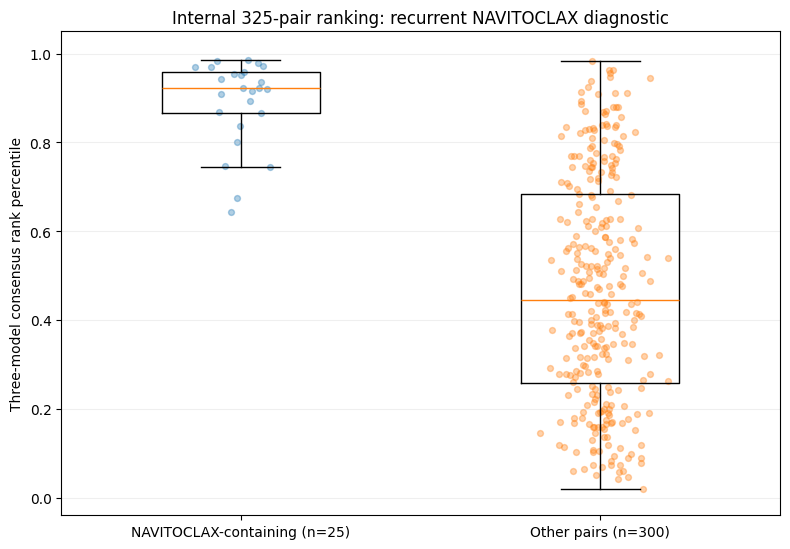

In [17]:
nav = pairs.loc[pairs["contains_navitoclax"], "ml_consensus"].to_numpy(dtype=float)
other = pairs.loc[~pairs["contains_navitoclax"], "ml_consensus"].to_numpy(dtype=float)
rng = np.random.default_rng(SEED)
fig, ax = plt.subplots(figsize=(8.0, 5.6))
ax.boxplot([nav, other], positions=[1,2], widths=.44, showfliers=False)
for pos, arr in ((1,nav),(2,other)):
    ax.scatter(rng.normal(pos, .065, size=len(arr)), arr, alpha=.35, s=18)
ax.set_xticks([1,2], [f"NAVITOCLAX-containing (n={len(nav)})", f"Other pairs (n={len(other)})"])
ax.set_ylabel("Three-model consensus rank percentile")
ax.set_title("Internal 325-pair ranking: recurrent NAVITOCLAX diagnostic")
ax.set_ylim(-.04,1.05)
ax.grid(axis="y", alpha=.2)
plt.tight_layout()
plt.show()

## 10. Propensity-adjusted and continuous-response support

**Not reconstructed from raw endpoints here.** The thesis uses an independently generated full-325-pair table containing *held-out HGB propensity-adjusted residuals* and measured mean/maximum `ΔfAUC` and `ΔEmax`. Only import these quantities from the correct upstream analysis. Required columns are `candidate_pair_key`, `residual_oof_score_mean` and `delta_fauc_mean_mean`; optional max/`ΔEmax` columns are displayed if available. Empirical percentile ranks use `rank(method='average', pct=True)` across **all 325 pairs**, not just the top 10.

In [18]:
secondary_top10 = None
if not SECONDARY_SUPPORT_PATH.strip():
    print("Skipped secondary support: set SECONDARY_SUPPORT_PATH to a verified 325-pair summary if available.")
else:
    support = read_local_table(SECONDARY_SUPPORT_PATH, "SECONDARY_SUPPORT_PATH")
    required = {"candidate_pair_key", "residual_oof_score_mean", "delta_fauc_mean_mean"}
    missing = required - set(support.columns)
    if missing:
        raise ValueError(f"Secondary support lacks verified thesis columns: {sorted(missing)}")
    support["candidate_pair_key"] = support["candidate_pair_key"].map(normalise_pair)
    if len(support) != 325 or support["candidate_pair_key"].nunique() != 325:
        raise ValueError("Secondary support must contain exactly 325 distinct canonical pair keys.")
    if set(support["candidate_pair_key"]) != set(consensus["candidate_pair_key"]):
        raise ValueError("Secondary-support pairs do not match the formal candidate space.")
    measures = [c for c in ("residual_oof_score_mean", "residual_oof_score_max",
                             "delta_fauc_mean_mean", "delta_fauc_mean_max",
                             "delta_emax_mean_mean", "delta_emax_mean_max") if c in support]
    for col in measures:
        val = pd.to_numeric(support[col], errors="coerce")
        if val.notna().sum() != 325:
            raise ValueError(f"{col}: cannot calculate full-325 percentiles with missing values.")
        support[col+"__percentile"] = val.rank(method="average", pct=True)
    secondary_rank = consensus.merge(support[["candidate_pair_key"]+measures+[c+"__percentile" for c in measures]],
                                     on="candidate_pair_key", how="left", validate="one_to_one")
    secondary_top10 = secondary_rank.nsmallest(10,"formal_rank").copy()
    display(secondary_top10[["formal_rank", "candidate_pair", "ml_consensus",
                              "residual_oof_score_mean__percentile", "delta_fauc_mean_mean__percentile"]])
    display(secondary_top10[["formal_rank", "candidate_pair"] +
                            [c+"__percentile" for c in measures]])
    print("Secondary-support values are post-hoc and have not changed the formal ranking.")

,formal_rank,candidate_pair,ml_consensus,residual_oof_score_mean__percentile,delta_fauc_mean_mean__percentile
0,1,NAVITOCLAX + OSI027,0.985597,0.947692,0.649231
1,2,DASATINIB + NAVITOCLAX,0.984053,0.944615,0.916923
2,3,MK2206 + SCH772984,0.983025,0.972308,0.993846
3,4,MK2206 + NAVITOCLAX,0.977881,0.987692,0.806154
4,5,LINSITINIB + NAVITOCLAX,0.972222,0.950769,0.840000
5,6,NAVITOCLAX + TRAMETINIB,0.970679,0.880000,0.956923
6,7,ERLOTINIB + NAVITOCLAX,0.969136,0.978462,0.781538
7,8,MK2206 + TRAMETINIB,0.962963,0.984615,0.984615
8,9,SCH772984 + TASELISIB,0.961934,0.993846,0.996923
9,10,LAPATINIB + NAVITOCLAX,0.958333,0.966154,0.966154


,formal_rank,candidate_pair,residual_oof_score_mean__percentile,residual_oof_score_max__percentile,delta_fauc_mean_mean__percentile,delta_fauc_mean_max__percentile,delta_emax_mean_mean__percentile,delta_emax_mean_max__percentile
0,1,NAVITOCLAX + OSI027,0.947692,0.920000,0.649231,0.680000,0.596923,0.455385
1,2,DASATINIB + NAVITOCLAX,0.944615,0.938462,0.916923,0.916923,0.889231,0.923077
2,3,MK2206 + SCH772984,0.972308,0.916923,0.993846,0.981538,1.000000,1.000000
3,4,MK2206 + NAVITOCLAX,0.987692,0.969231,0.806154,0.913846,0.806154,0.907692
4,5,LINSITINIB + NAVITOCLAX,0.950769,0.950769,0.840000,0.864615,0.812308,0.775385
5,6,NAVITOCLAX + TRAMETINIB,0.880000,0.864615,0.956923,0.953846,0.935385,0.901538
6,7,ERLOTINIB + NAVITOCLAX,0.978462,0.984615,0.781538,0.855385,0.753846,0.707692
7,8,MK2206 + TRAMETINIB,0.984615,1.000000,0.984615,0.987692,0.990769,0.996923
8,9,SCH772984 + TASELISIB,0.993846,0.941538,0.996923,1.000000,0.987692,0.984615
9,10,LAPATINIB + NAVITOCLAX,0.966154,0.929231,0.966154,0.892308,0.966154,0.852308


Secondary-support values are post-hoc and have not changed the formal ranking.
